# 💻 Analyse Immobilière à Casablanca & Modélisation Prédictive
Ce notebook présente une analyse de bout en bout des annonces immobilières à Casablanca, suivie du développement d'un modèle prédictif.

In [6]:
!pip install pandas
!pip install numpy
!pip install matplotlib
!pip install scikit-learn

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [8]:
from google.colab import files
files.upload()

Saving mubawab_listings.csv to mubawab_listings.csv


{'mubawab_listings.csv': b'Type,Localisation,Latitude,Longitude,Title,Price,Tags\nAppartements Casablanca,Casablanca Finance City \xc3\xa0 Casablanca,,,Somptueux appartement \xc3\xa0 louer au tour v\xc3\xa9g\xc3\xa9tal,22 000 DH,"[\'219 m\xc2\xb2\', \'4 Pi\xc3\xa8ces\', \'3 Chambres\', \'3 Salles de bains\', \'Nouveau\', ""Moins d\'un an"", \'11\xc3\xa8me \xc3\xa9tage\']"\nAppartements Casablanca,Anfa \xc3\xa0 Casablanca,,,A vendre appartement 86m face ELBILIA lahjajma,1 230 000 DH,"[\'86 m\xc2\xb2\', \'3 Pi\xc3\xa8ces\', \'2 Chambres\', \'2 Salles de bains\', \'Bon \xc3\xa9tat\', \'10-20 ans\', \'1er \xc3\xa9tage\']"\nAppartements Casablanca,La Gironde \xc3\xa0 Casablanca,,,A vendre bel appartement 2 chambres Gironde,900 000 DH,"[\'86 m\xc2\xb2\', \'3 Pi\xc3\xa8ces\', \'2 Chambres\', \'1 Salle de bain\', \'Bon \xc3\xa9tat\', \'10-20 ans\', \'5\xc3\xa8me \xc3\xa9tage\']"\nAppartements Casablanca,Bourgogne Ouest \xc3\xa0 Casablanca,,,A vendre appartement 180m clinique Badr pas cher,2 40

In [12]:
df = pd.read_csv('mubawab_listings.csv')

## 📊 1. Analyse Exploratoire des Données (EDA) & Nettoyage
Dans cette section, nous chargeons les données brutes, analysons les valeurs manquantes, nettoyons la colonne de prix et extrayons les caractéristiques clés des logements à partir des étiquettes (Tags).

In [19]:
# Afficher les informations globales sur le DataFrame (colonnes, types et valeurs manquantes)
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3300 entries, 0 to 3299
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Type          3286 non-null   object 
 1   Localisation  3300 non-null   object 
 2   Latitude      1766 non-null   float64
 3   Longitude     1766 non-null   float64
 4   Title         3300 non-null   object 
 5   Price         3134 non-null   object 
 6   Tags          3300 non-null   object 
dtypes: float64(2), object(5)
memory usage: 180.6+ KB


None

In [16]:
# Afficher un échantillon propre des premières lignes
display(df.head())

,Type,Localisation,Latitude,Longitude,Title,Price,Tags
0,Appartements Casablanca,Casablanca Finance City à Casablanca,NaN,NaN,Somptueux appartement à louer au tour végétal,22 000 DH,"['219 m²', '4 Pièces', '3 Chambres', '3 Salles..."
1,Appartements Casablanca,Anfa à Casablanca,NaN,NaN,A vendre appartement 86m face ELBILIA lahjajma,1 230 000 DH,"['86 m²', '3 Pièces', '2 Chambres', '2 Salles ..."
2,Appartements Casablanca,La Gironde à Casablanca,NaN,NaN,A vendre bel appartement 2 chambres Gironde,900 000 DH,"['86 m²', '3 Pièces', '2 Chambres', '1 Salle d..."
3,Appartements Casablanca,Bourgogne Ouest à Casablanca,NaN,NaN,A vendre appartement 180m clinique Badr pas cher,2 400 000 DH,"['180 m²', '5 Pièces', '3 Chambres', '3 Salles..."
4,Appartements Casablanca,Les princesses à Casablanca,33.574209,-7.644182,Appartement 3 chambres yaacoub almansour pas cher,1 550 000 DH,"['120 m²', '5 Pièces', '3 Chambres', '2 Salles..."


In [20]:
# 1. Calculer le nombre et le pourcentage de valeurs manquantes par colonne
missing_data = pd.DataFrame({
    'Valeurs Manquantes': df.isnull().sum(),
    'Pourcentage (%)': (df.isnull().sum() / len(df)) * 100
})
display(missing_data)

,Valeurs Manquantes,Pourcentage (%)
Type,14,0.424242
Localisation,0,0.000000
Latitude,1534,46.484848
Longitude,1534,46.484848
Title,0,0.000000
Price,166,5.030303
Tags,0,0.000000


In [24]:
# 2. Nettoyage de la colonne 'Price' pour la convertir en format numérique
# On retire 'DH', les espaces et on convertit en float
df['Price_Numeric'] = df['Price'].astype(str).str.replace(' DH', '').str.replace(' ', '')
df['Price_Numeric'] = pd.to_numeric(df['Price_Numeric'], errors='coerce')
# Afficher un résumé statistique de la colonne des prix
display(df[['Price', 'Price_Numeric']].head())
print("\nStatistiques descriptives des prix en DH :")
display(df['Price_Numeric'].describe())


,Price,Price_Numeric
0,22 000 DH,22000.0
1,1 230 000 DH,1230000.0
2,900 000 DH,900000.0
3,2 400 000 DH,2400000.0
4,1 550 000 DH,1550000.0



Statistiques descriptives des prix en DH :


,Price_Numeric
count,3.132000e+03
mean,4.558825e+06
std,6.796934e+06
min,1.600000e+03
25%,1.250000e+06
50%,2.190750e+06
75%,4.800000e+06
max,7.140000e+07


In [25]:
import re

def extract_features(tags_str):
    # Convertir la chaîne de caractères (représentant une liste) en texte brut
    tags_str = str(tags_str)

    # Initialisation des variables
    surface = np.nan
    pieces = np.nan
    chambres = np.nan
    salles_bains = np.nan

    # Recherche des motifs via expressions régulières
    surf_match = re.search(r'(\d+)\s*m²', tags_str)
    pieces_match = re.search(r'(\d+)\s*Pièce', tags_str)
    chamb_match = re.search(r'(\d+)\s*Chambre', tags_str)
    baths_match = re.search(r'(\d+)\s*Salle', tags_str)

    if surf_match: surface = float(surf_match.group(1))
    if pieces_match: pieces = float(pieces_match.group(1))
    if chamb_match: chambres = float(chamb_match.group(1))
    if baths_match: salles_bains = float(baths_match.group(1))

    return pd.Series([surface, pieces, chambres, salles_bains])

# Appliquer la fonction pour créer de nouvelles colonnes
df[['Surface_m2', 'Pieces', 'Chambres', 'Salles_de_bains']] = df['Tags'].apply(extract_features)

# Afficher un échantillon des données extraites
display(df[['Tags', 'Surface_m2', 'Pieces', 'Chambres', 'Salles_de_bains']].head())

,Tags,Surface_m2,Pieces,Chambres,Salles_de_bains
0,"['219 m²', '4 Pièces', '3 Chambres', '3 Salles...",219.0,4.0,3.0,3.0
1,"['86 m²', '3 Pièces', '2 Chambres', '2 Salles ...",86.0,3.0,2.0,2.0
2,"['86 m²', '3 Pièces', '2 Chambres', '1 Salle d...",86.0,3.0,2.0,1.0
3,"['180 m²', '5 Pièces', '3 Chambres', '3 Salles...",180.0,5.0,3.0,3.0
4,"['120 m²', '5 Pièces', '3 Chambres', '2 Salles...",120.0,5.0,3.0,2.0


In [26]:
# Afficher les statistiques de nos nouvelles variables numériques
display(df[['Surface_m2', 'Pieces', 'Chambres', 'Salles_de_bains', 'Price_Numeric']].describe())

,Surface_m2,Pieces,Chambres,Salles_de_bains,Price_Numeric
count,3300.000000,3147.000000,3290.000000,3196.000000,3.132000e+03
mean,283.449697,4.620909,2.932827,2.300688,4.558825e+06
std,431.839570,2.198996,1.387754,1.151720,6.796934e+06
min,30.000000,1.000000,1.000000,1.000000,1.600000e+03
25%,91.000000,3.000000,2.000000,2.000000,1.250000e+06
50%,129.000000,4.000000,3.000000,2.000000,2.190750e+06
75%,258.000000,6.000000,4.000000,3.000000,4.800000e+06
max,5400.000000,17.000000,18.000000,10.000000,7.140000e+07


In [29]:
# 1. Analyse par quartier (Top 10 des localisations avec le prix moyen le plus élevé)
# On filtre les quartiers ayant au moins 5 annonces pour éviter les valeurs aberrantes dues à une seule annonce
stats_par_quartier = df.groupby('Localisation').agg(
    Nombre_Annonces=('Price_Numeric', 'count'),
    Prix_Moyen_DH=('Price_Numeric', 'mean'),
    Surface_Moyenne_m2=('Surface_m2', 'mean')
).reset_index()

top_quartiers_chers = stats_par_quartier[stats_par_quartier['Nombre_Annonces'] >= 5].sort_values(by='Prix_Moyen_DH', ascending=False).head(10)
display(top_quartiers_chers)

,Localisation,Nombre_Annonces,Prix_Moyen_DH,Surface_Moyenne_m2
12,Anfa Supérieur à Casablanca,30,3.190333e+07,1584.060606
77,Longchamps (Hay Al Hanâa) à Casablanca,39,1.285128e+07,730.846154
13,Anfa à Casablanca,92,1.161748e+07,606.270833
3,Ain Diab Extension à Casablanca,36,1.024861e+07,653.444444
90,Polo à Casablanca,41,9.996341e+06,888.268293
91,Port à Casablanca,15,9.518667e+06,296.733333
4,Ain Diab à Casablanca,155,8.893710e+06,496.732484
24,Californie à Casablanca,348,8.353381e+06,634.541899
73,Les Crêtes à Casablanca,7,7.954286e+06,659.285714
23,CIL (Hay Salam) à Casablanca,98,7.857347e+06,441.928571


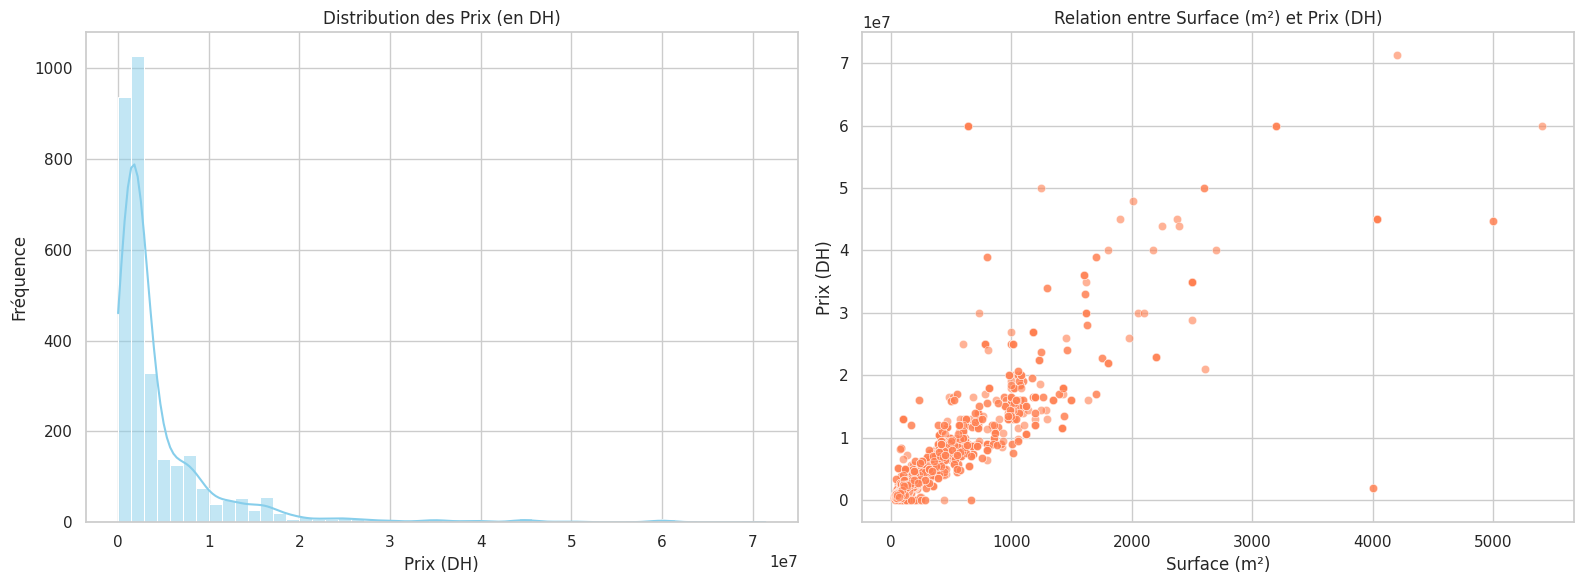

In [30]:
# 2. Visualisation des données avec Seaborn et Matplotlib
import seaborn as sns
import matplotlib.pyplot as plt

# Définir le style des graphiques
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Graphique 1 : Distribution des Prix
sns.histplot(df['Price_Numeric'].dropna(), bins=50, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution des Prix (en DH)')
axes[0].set_xlabel('Prix (DH)')
axes[0].set_ylabel('Fréquence')

# Graphique 2 : Relation entre la Surface et le Prix
sns.scatterplot(data=df, x='Surface_m2', y='Price_Numeric', alpha=0.6, ax=axes[1], color='coral')
axes[1].set_title('Relation entre Surface (m²) et Prix (DH)')
axes[1].set_xlabel('Surface (m²)')
axes[1].set_ylabel('Prix (DH)')

plt.tight_layout()
plt.show()

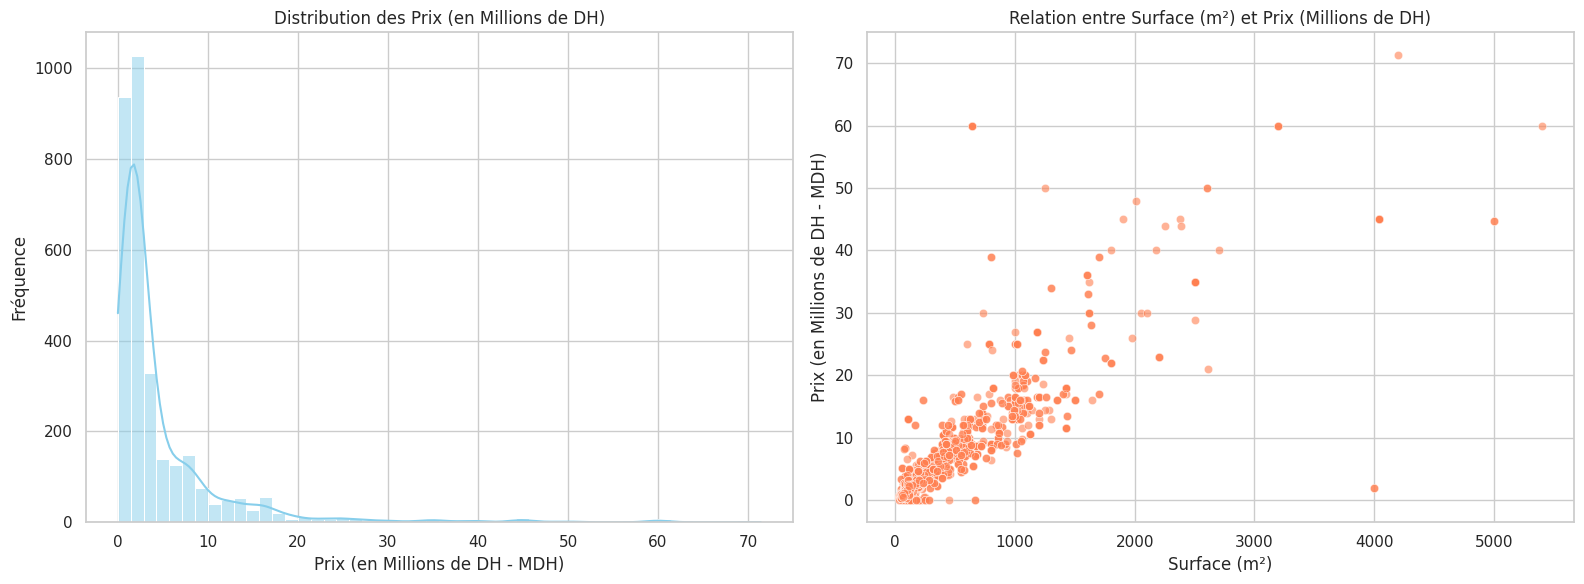

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

# Créer une nouvelle colonne pour les prix exprimés en Millions de DH (MDH) pour une lecture simplifiée
df['Price_Million_DH'] = df['Price_Numeric'] / 1_000_000

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Graphique 1 : Distribution des Prix (en Millions de DH)
sns.histplot(df['Price_Million_DH'].dropna(), bins=50, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution des Prix (en Millions de DH)')
axes[0].set_xlabel('Prix (en Millions de DH - MDH)')
axes[0].set_ylabel('Fréquence')

# Graphique 2 : Relation entre la Surface et le Prix
sns.scatterplot(data=df, x='Surface_m2', y='Price_Million_DH', alpha=0.6, ax=axes[1], color='coral')
axes[1].set_title('Relation entre Surface (m²) et Prix (Millions de DH)')
axes[1].set_xlabel('Surface (m²)')
axes[1].set_ylabel('Prix (en Millions de DH - MDH)')

plt.tight_layout()
plt.show()

## 🏘️ 2. Analyse Comparative : Appartements vs. Villas
Nous analysons ici les différences majeures de budget et d'espace entre les appartements et les villas dans la métropole de Casablanca.

In [33]:
# Création d'une colonne simplifiée pour le type de bien
df['Type_Simple'] = df['Type'].apply(lambda x: 'Villa / Maison' if 'Villa' in str(x) else ('Appartement' if 'Appartement' in str(x) else 'Autre'))

# Calcul des statistiques descriptives par type de bien
comparatif = df.groupby('Type_Simple').agg(
    Nombre_Annonces=('Price_Numeric', 'count'),
    Prix_Median_MDH=('Price_Million_DH', 'median'),
    Prix_Moyen_MDH=('Price_Million_DH', 'mean'),
    Surface_Moyenne_m2=('Surface_m2', 'mean')
).reset_index()

display(comparatif)

,Type_Simple,Nombre_Annonces,Prix_Median_MDH,Prix_Moyen_MDH,Surface_Moyenne_m2
0,Appartement,2325,1.7,1.998653,126.136143
1,Autre,81,3.0,4.134527,236.800000
2,Villa / Maison,726,9.1,12.805062,812.355795


/tmp/ipykernel_16266/66772693.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df['Type_Simple'].isin(['Appartement', 'Villa / Maison'])], x='Type_Simple', y='Price_Million_DH', ax=axes[0], palette='Set2')


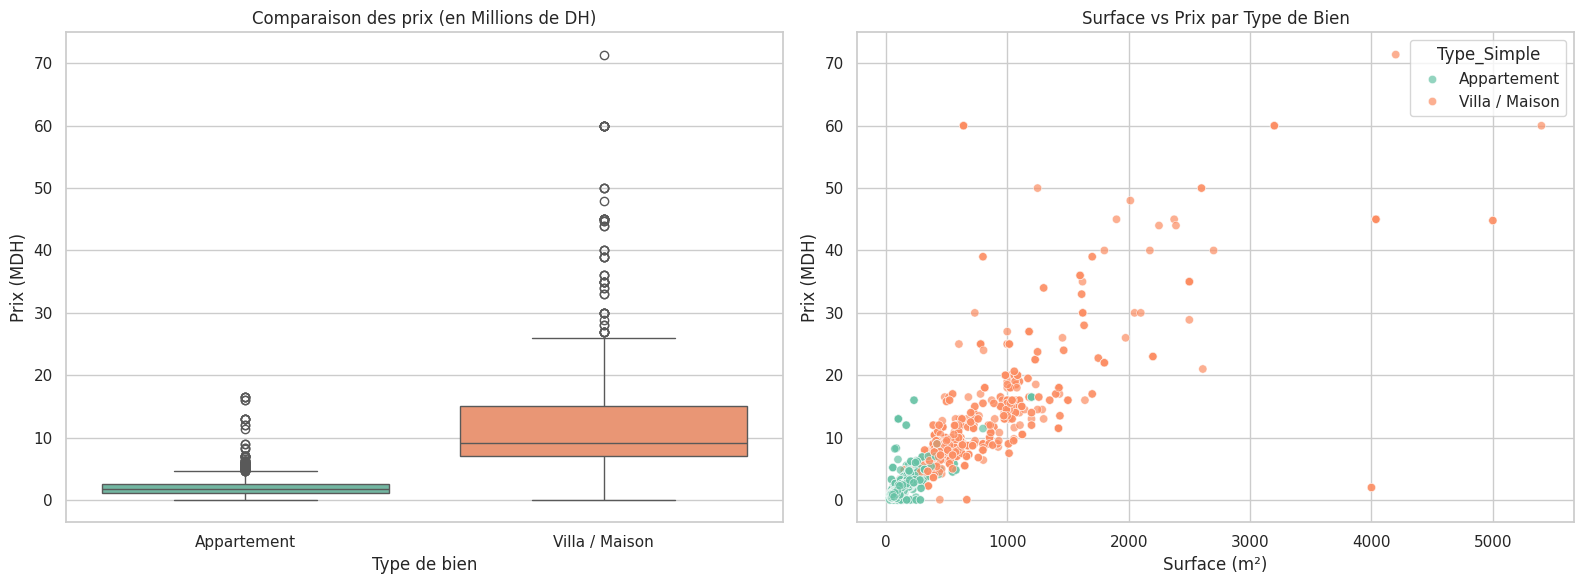

In [34]:
# Visualisation de la comparaison de prix et surface
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot des prix
sns.boxplot(data=df[df['Type_Simple'].isin(['Appartement', 'Villa / Maison'])], x='Type_Simple', y='Price_Million_DH', ax=axes[0], palette='Set2')
axes[0].set_title('Comparaison des prix (en Millions de DH)')
axes[0].set_ylabel('Prix (MDH)')
axes[0].set_xlabel('Type de bien')

# Scatter plot surface vs prix différencié par type
sns.scatterplot(data=df[df['Type_Simple'].isin(['Appartement', 'Villa / Maison'])], x='Surface_m2', y='Price_Million_DH', hue='Type_Simple', alpha=0.7, ax=axes[1], palette='Set2')
axes[1].set_title('Surface vs Prix par Type de Bien')
axes[1].set_xlabel('Surface (m²)')
axes[1].set_ylabel('Prix (MDH)')

plt.tight_layout()
plt.show()

## 🤖 3. Modélisation Prédictive (Machine Learning)
Entraînement d'un algorithme de régression robuste (Random Forest) pour estimer le prix des propriétés à partir de leurs caractéristiques.

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# 1. Sélection des caractéristiques et de la cible
features = ['Surface_m2', 'Chambres', 'Salles_de_bains', 'Type_Simple', 'Localisation']
target = 'Price_Million_DH'

# Filtrer les données pour n'avoir que les lignes où le prix est renseigné
df_ml = df.dropna(subset=[target]).copy()

X = df_ml[features]
y = df_ml[target]

# 2. Définition des transformations (Pipeline)
numerical_features = ['Surface_m2', 'Chambres', 'Salles_de_bains']
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_features = ['Type_Simple', 'Localisation']
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# 3. Création du pipeline complet avec le modèle
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

# 4. Séparation en données d'entraînement et de test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Entraînement du modèle
model.fit(X_train, y_train)

# 6. Prédictions et Évaluation
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"--- Performances du Modèle ---")
print(f"Erreur Absolue Moyenne (MAE) : {mae:.2f} Millions de DH (soit environ {mae*1000000:,.0f} DH)")
print(f"Score R² (Coefficient de détermination) : {r2:.2%}")

--- Performances du Modèle ---
Erreur Absolue Moyenne (MAE) : 0.60 Millions de DH (soit environ 604,450 DH)
Score R² (Coefficient de détermination) : 91.45%


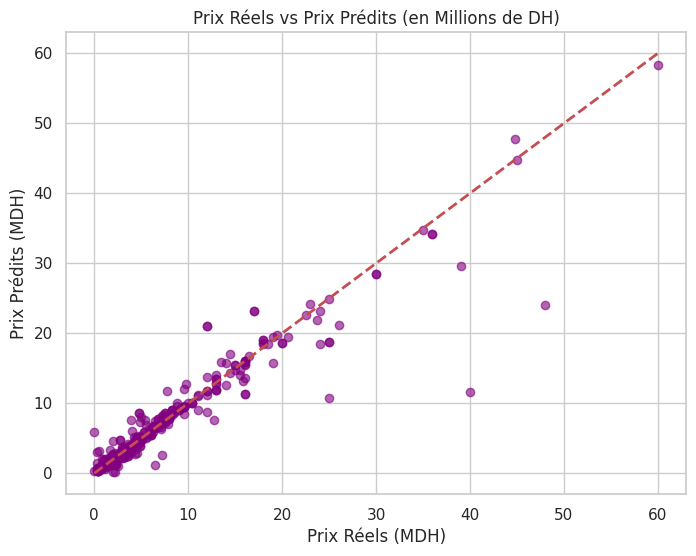

In [36]:
# Graphique de comparaison : Valeurs réelles vs Prédictions
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Prix Réels vs Prix Prédits (en Millions de DH)')
plt.xlabel('Prix Réels (MDH)')
plt.ylabel('Prix Prédits (MDH)')
plt.grid(True)
plt.show()

### 📈 Évaluation des Performances du Modèle
Comparaison visuelle entre les prix réels et les prix prédits par le modèle sur le jeu de test.

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# 1. Sélection des caractéristiques et de la cible
features = ['Surface_m2', 'Chambres', 'Salles_de_bains', 'Type_Simple', 'Localisation']
target = 'Price_Million_DH'

# Filtrer les données pour n'avoir que les lignes où le prix est renseigné
df_ml = df.dropna(subset=[target]).copy()

X = df_ml[features]
y = df_ml[target]

# 2. Définition des transformations (Pipeline)
numerical_features = ['Surface_m2', 'Chambres', 'Salles_de_bains']
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_features = ['Type_Simple', 'Localisation']
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# 3. Création du pipeline complet avec le modèle
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

# 4. Séparation en données d'entraînement et de test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Entraînement du modèle
model.fit(X_train, y_train)

# 6. Prédictions et Évaluation
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"--- Performances du Modèle ---")
print(f"Erreur Absolue Moyenne (MAE) : {mae:.2f} Millions de DH (soit environ {mae*1000000:,.0f} DH)")
print(f"Score R² (Coefficient de détermination) : {r2:.2%}")

--- Performances du Modèle ---
Erreur Absolue Moyenne (MAE) : 0.60 Millions de DH (soit environ 604,450 DH)
Score R² (Coefficient de détermination) : 91.45%


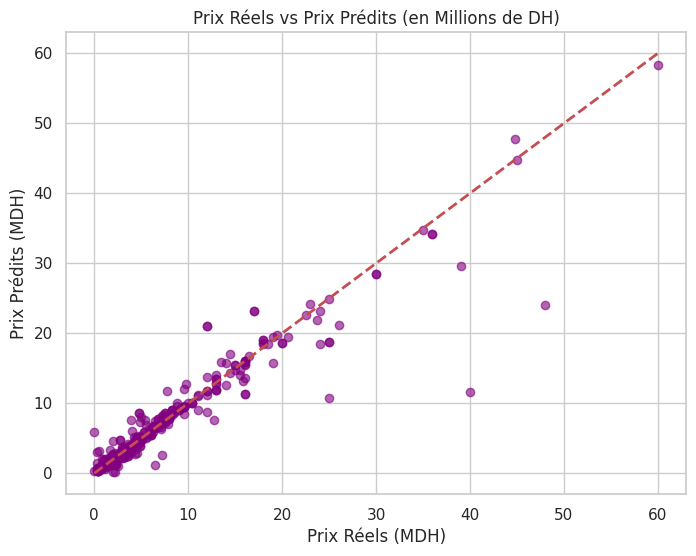

In [38]:
# Graphique de comparaison : Valeurs réelles vs Prédictions
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Prix Réels vs Prix Prédits (en Millions de DH)')
plt.xlabel('Prix Réels (MDH)')
plt.ylabel('Prix Prédits (MDH)')
plt.grid(True)
plt.show()

## 🔮 4. Simulateur de Prix Interactif
Cette fonction permet d'estimer instantanément la valeur d'un bien immobilier personnalisé à Casablanca.

In [39]:
def estimer_prix_bien(surface, chambres, salles_de_bains, type_bien, quartier):
    # Création du DataFrame pour la prédiction
    data_input = pd.DataFrame([{
        'Surface_m2': surface,
        'Chambres': chambres,
        'Salles_de_bains': salles_de_bains,
        'Type_Simple': type_bien,
        'Localisation': quartier
    }])

    # Prédiction
    prediction_mdh = model.predict(data_input)[0]

    print(f"--- ESTIMATION DE VOTRE BIEN IMMOBILIER ---")
    print(f"Quartier       : {quartier}")
    print(f"Type de bien   : {type_bien}")
    print(f"Caractéristiques: {surface} m² | {chambres} Ch | {salles_de_bains} SDB")
    print(f"=> Prix Estimé : {prediction_mdh:.2f} Millions de DH (soit {prediction_mdh*1_000_000:,.0f} DH)")

# Exemple de simulation (N'hésitez pas à modifier ces paramètres !)
estimer_prix_bien(
    surface=120,
    chambres=3,
    salles_de_bains=2,
    type_bien='Appartement',
    quartier='Maârif à Casablanca'
)

--- ESTIMATION DE VOTRE BIEN IMMOBILIER ---
Quartier       : Maârif à Casablanca
Type de bien   : Appartement
Caractéristiques: 120 m² | 3 Ch | 2 SDB
=> Prix Estimé : 1.97 Millions de DH (soit 1,973,226 DH)


### 5. Simulateur d'Estimation de Prix
Utilisez la fonction ci-dessous pour prédire la valeur marchande d'un bien immobilier spécifique à Casablanca.

In [42]:
# 5. Simulateur Final d'Estimation Immobilière

### 5. Simulateur d'Estimation de Prix
Utilisez la fonction ci-dessous pour prédire la valeur marchande d'un bien immobilier spécifique à Casablanca.

In [41]:
def estimer_prix_bien(surface, chambres, salles_de_bains, type_bien, quartier):
    """
    Estime le prix d'un bien immobilier à Casablanca à l'aide du modèle Random Forest entraîné.
    """
    # Création du DataFrame pour la prédiction
    data_input = pd.DataFrame([{
        'Surface_m2': surface,
        'Chambres': chambres,
        'Salles_de_bains': salles_de_bains,
        'Type_Simple': type_bien,
        'Localisation': quartier
    }])

    # Prédiction avec le modèle
    prediction_mdh = model.predict(data_input)[0]

    print(f"--- ESTIMATION DE VOTRE BIEN IMMOBILIER ---")
    print(f"Quartier       : {quartier}")
    print(f"Type de bien   : {type_bien}")
    print(f"Caractéristiques: {surface} m² | {chambres} Ch | {salles_de_bains} SDB")
    print(f"=> Prix Estimé : {prediction_mdh:.2f} Millions de DH (soit {prediction_mdh*1_000_000:,.0f} DH)")

# Exemple d'utilisation du simulateur
estimer_prix_bien(
    surface=120,
    chambres=3,
    salles_de_bains=2,
    type_bien='Appartement',
    quartier='Maârif à Casablanca'
)

--- ESTIMATION DE VOTRE BIEN IMMOBILIER ---
Quartier       : Maârif à Casablanca
Type de bien   : Appartement
Caractéristiques: 120 m² | 3 Ch | 2 SDB
=> Prix Estimé : 1.97 Millions de DH (soit 1,973,226 DH)
